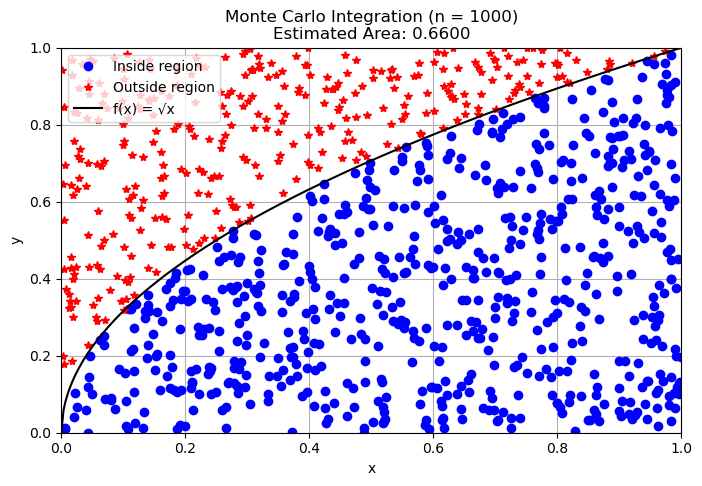

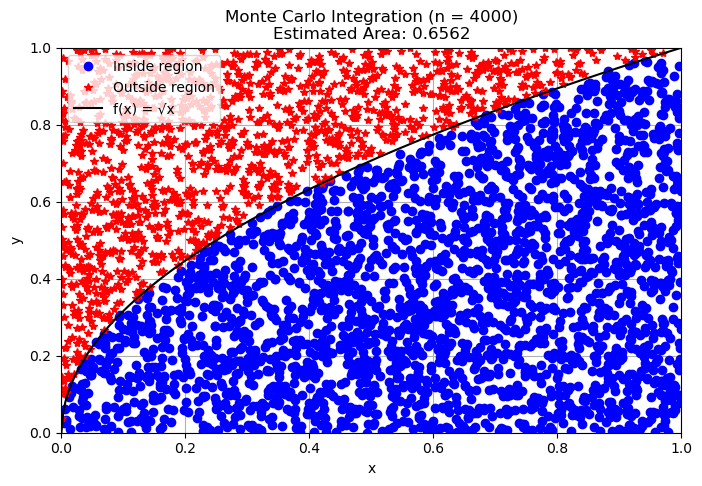

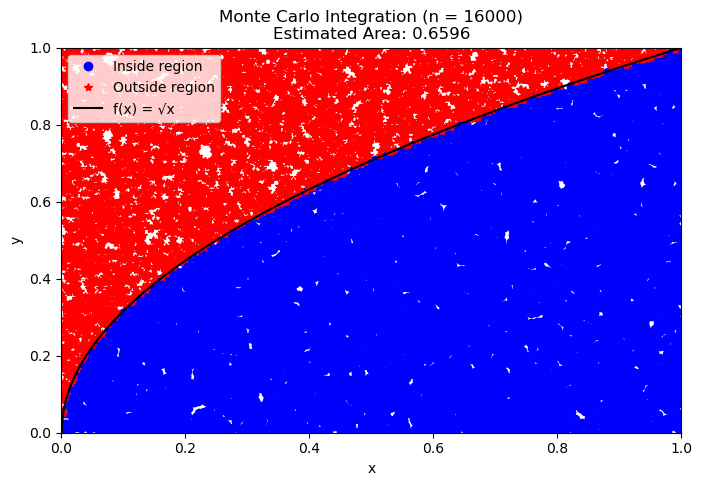

--------------------------------------------------
Function f(x) = sqrt(x)
Exact Integral (fraction) = 2/3
Exact Integral (float) = 0.6667
--------------------------------------------------
Error for n_1 (1000 points) = 0.0067
Error for n_2 (4000 points) = 0.0104
Error for n_3 (16000 points) = 0.0071
--------------------------------------------------


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

#Set random seed for reproducibility
np.random.seed(0)

#Function to generate a random number in the interval [a, b]
def random(a, b):
    return a + (b - a) * np.random.random()

#Definition of f(x) = √x
def f(x):
    return np.sqrt(x)

#List of sample sizes 
n_values = [1000, 4000, 16000]
estimates = []

#1. We define the plotting function mygraph(...)
#Arguments:
# n_i: current sample size (1000, 4000, or 16000)
# x_in, y_in: coordinates of sample points inside the region (y <= sqrt(x))
# x_out, y_out: coordinates of sample points outside the region (y > sqrt(x))
# estimate: estimated value of the integral for the current sample size
def mygraph(n_i, x_in, y_in, x_out, y_out, estimate):
    plt.figure(figsize = (8, 5))
    
    #We plot the classified sample points
    plt.plot(x_in, y_in, 'bo', label='Inside region')    # blue 'o' for inside points
    plt.plot(x_out, y_out, 'r*', label='Outside region') # red '*' for outside points
    
    #We plot the graph of f(x) = sqrt(x)
    x = np.linspace(0, 1, 300)
    plt.plot(x, f(x), 'k', label="f(x) = √x")
    
    #Axes limits, labels, title, and legend
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Monte Carlo Integration (n = %d)\nEstimated Area: %.4f' % (n_i, estimate))
    plt.legend(loc='upper left')
    plt.grid()
    plt.show()

#2. We execute the Monte Carlo simulation for each sample size n_i
for i in range(len(n_values)):
    n_i = n_values[i]
    #Initialize counters for total points and points inside the region of interest
    tot = cntIn = 0
    
    #Initialize storage lists for points
    x_in, y_in = [], [] #inside points
    x_out, y_out = [], [] #outside points

    #Monte Carlo sampling loop
    for p_iter in range(n_i):
        #Generate random point (p_x, p_y) in [0, 1]x[0, 1]
        p_x, p_y = random(0, 1), random(0, 1)
        tot += 1 # Increment total points
        
        #Check if the random point is inside the region defined by f(x) and x'x axis (y=0) (0 <= p_y <= sqrt(p_x))
        if p_y <= f(p_x):
            cntIn += 1    #Increment points inside counter
            x_in.append(p_x)
            y_in.append(p_y)
        else:
            x_out.append(p_x)
            y_out.append(p_y)
            
    # Estimate the integral for this experiment: Area = Box_Area * (cntIn / tot), where Box_Area = width*height = [1-0]*[1-0] = 1
    integral_exp = (cntIn/tot)
    estimates.append(integral_exp)

    #We call mygraph() for the current sample size n_i
    mygraph(n_i, x_in, y_in, x_out, y_out, integral_exp)

#3. Analytical verification using SymPy
print('-'*50)
x_symbol = sp.Symbol('x')
f_symbol = sp.sqrt(x_symbol)

#Analytical integral of sqrt(x) from 0 to 1
exact_integral = sp.integrate(f_symbol, (x_symbol, 0, 1))
exact_float_value = float(exact_integral)
print("Function f(x) =", f_symbol)
print("Exact Integral (fraction) =", exact_integral)
print(f"Exact Integral (float) = {exact_float_value:.4f}")
print('-'*50)

#Error calculation
#We compute and display the absolute error for each sample size n_i
for j in range(len(n_values)):
    index =  j + 1    # 1-based indexing 1, 2, 3
    error = abs(exact_float_value - estimates[j])
    print(f"Error for n_{index} ({n_values[j]} points) = {error:.4f}")
print('-'*50)